Tensorflow equivalent

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_data_path = 'flower_photos_train'
val_data_path = 'flower_photos_test'

def create_dataset(data_path, batch_size=18, training=True):
    if training:
        datagen = ImageDataGenerator(
            rescale=1./255,
            shear_range=0.2,
            zoom_range=0.2,
            horizontal_flip=True,
            validation_split=0.2
        )
    else:
        datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

    dataset = datagen.flow_from_directory(
        data_path,
        target_size=(224, 224),
        batch_size=batch_size,
        class_mode='categorical',
        subset='training' if training else 'validation'
    )
    return dataset

dataset_train = create_dataset(train_data_path)
dataset_val = create_dataset(val_data_path, training=False)


ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

base_model = MobileNetV2(weights='imagenet', include_top=False)

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(5, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

for layer in base_model.layers:
    layer.trainable = False

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.fit(dataset_train, epochs=5, validation_data=dataset_val)


9406464/9406464 [==============================] - 1s 0us/step
Epoch 1/5
161/161 [==============================] - 75s 443ms/step - loss: 0.5947 - accuracy: 0.7981 - val_loss: 0.3460 - val_accuracy: 0.9000
Epoch 2/5
161/161 [==============================] - 44s 275ms/step - loss: 0.3093 - accuracy: 0.8913 - val_loss: 0.5627 - val_accuracy: 0.8000
Epoch 3/5
161/161 [==============================] - 44s 275ms/step - loss: 0.2309 - accuracy: 0.9182 - val_loss: 0.3628 - val_accuracy: 0.9000
Epoch 4/5
161/161 [==============================] - 44s 275ms/step - loss: 0.1951 - accuracy: 0.9313 - val_loss: 0.6163 - val_accuracy: 0.9000
Epoch 5/5
161/161 [==============================] - 44s 275ms/step - loss: 0.1593 - accuracy: 0.9444 - val_loss: 0.3801 - val_accuracy: 0.7000


1/1 [==============================] - 1s 1s/step


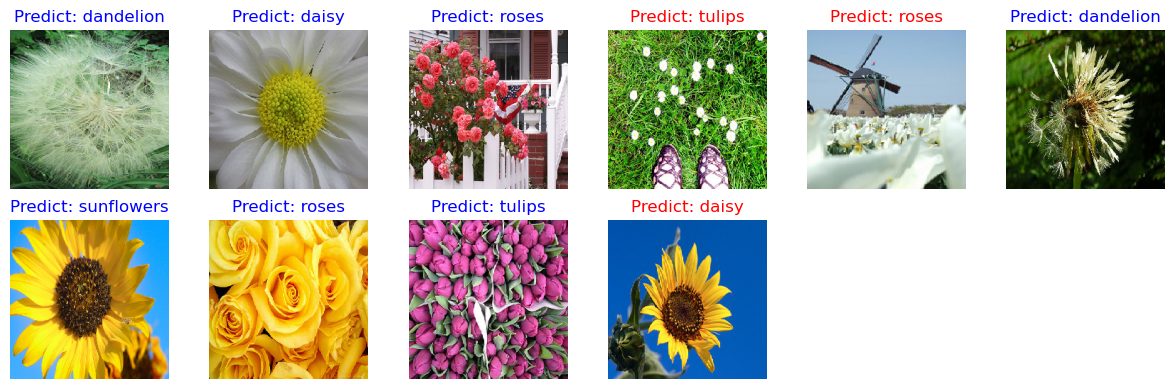

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_model(model, dataset):
    data = next(iter(dataset))
    images, labels = data
    predictions = model.predict(images)
    pred_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(labels, axis=1)
    class_names = list(dataset.class_indices.keys())

    plt.figure(figsize=(15, 7))
    for i in range(len(images)):
        plt.subplot(3, 6, i + 1)
        color = 'blue' if pred_classes[i] == true_classes[i] else 'red'
        plt.title(f'Predict: {class_names[pred_classes[i]]}', color=color)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

visualize_model(model, dataset_val)


In [4]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_data_path = 'flower_photos_train'
val_data_path = 'flower_photos_test'

def create_dataset(data_path, batch_size=18, training=True):
    transform = transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]) if training else transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    dataset = datasets.ImageFolder(data_path, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=training, num_workers=4)
    return dataloader

dataset_train = create_dataset(train_data_path)
dataset_val = create_dataset(val_data_path, training=False)


ModuleNotFoundError: No module named 'torch'

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.mobilenet_v2(pretrained=True)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 5)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(5):
    model.train()
    running_loss = 0.0
    for inputs, labels in dataset_train:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(dataset_train)}")

model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in dataset_val:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f"Accuracy: {100 * correct / total}%")


c:\Users\lmo\anaconda3\envs\mindspore_env\lib\site-packages\torchvision\models\_utils.py:209: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  f"The parameter '{pretrained_param}' is deprecated since 0.13 and may be removed in the future, "
c:\Users\lmo\anaconda3\envs\mindspore_env\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\lmo/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth
100.0%


Epoch 1, Loss: 0.7969854346555264
Epoch 2, Loss: 0.6209321958360388
Epoch 3, Loss: 0.557112534470226
Epoch 4, Loss: 0.5321212613315724
Epoch 5, Loss: 0.5036732868398007
Accuracy: 88.46153846153847%


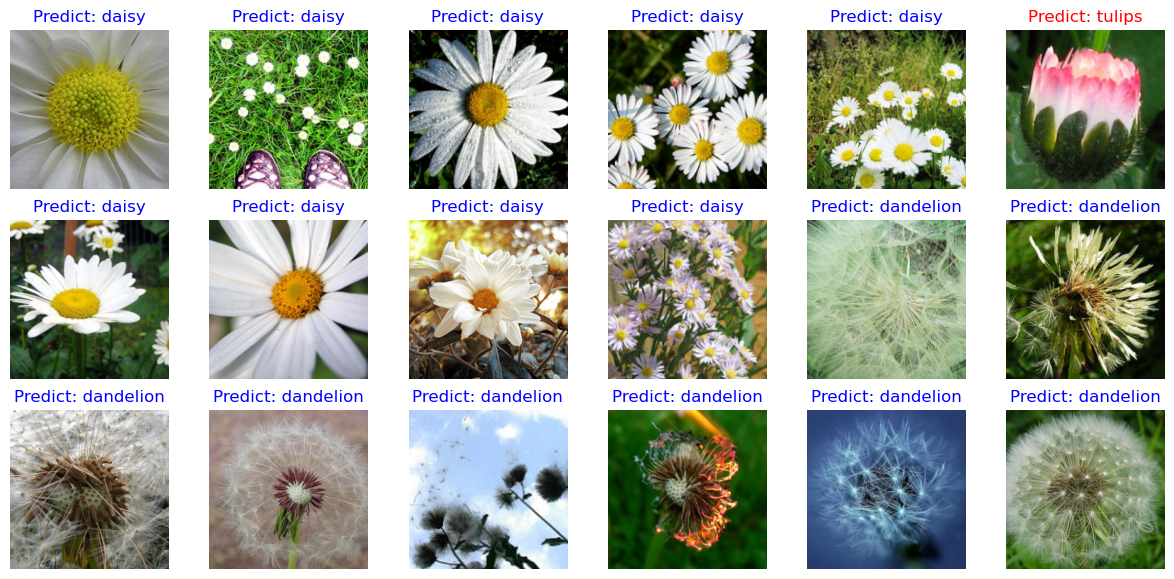

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_model(model, dataset):
    class_names = dataset.dataset.classes
    model.eval()
    data = next(iter(dataset))
    images, labels = data
    outputs = model(images.to(device))
    _, preds = torch.max(outputs, 1)
    preds = preds.cpu().numpy()
    labels = labels.numpy()

    plt.figure(figsize=(15, 7))
    for i in range(len(images)):
        plt.subplot(3, 6, i + 1)
        color = 'blue' if preds[i] == labels[i] else 'red'
        plt.title(f'Predict: {class_names[preds[i]]}', color=color)
        img = images[i].permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.axis('off')
    plt.show()

visualize_model(model, dataset_val)
